In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from clustering.utils import generate_data, SpaceTimeSVD, ClusteringCPQR

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 


In [2]:
np.random.seed(0)

In [3]:
movie = np.zeros((2_000, 9, 2))

In [4]:
data, truth = generate_data(
    n_timepoints=1_000,
    n_components=2,
    noise=0,
    n_pixels=1,
    n_pixels_bg=0
)

In [5]:
data.shape

(2, 2000)

In [6]:
movie.shape

(2000, 9, 2)

In [7]:
movie[:, :, 0].shape

(2000, 9)

In [8]:
movie[:, 0:3] = data[0, None, None].T
movie[:, 3:6] = data[1, None, None].T / 2
movie[:, 6:] = data[0, None, None].T + (data[1, None, None].T / 2)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='600px', css_width='700px')
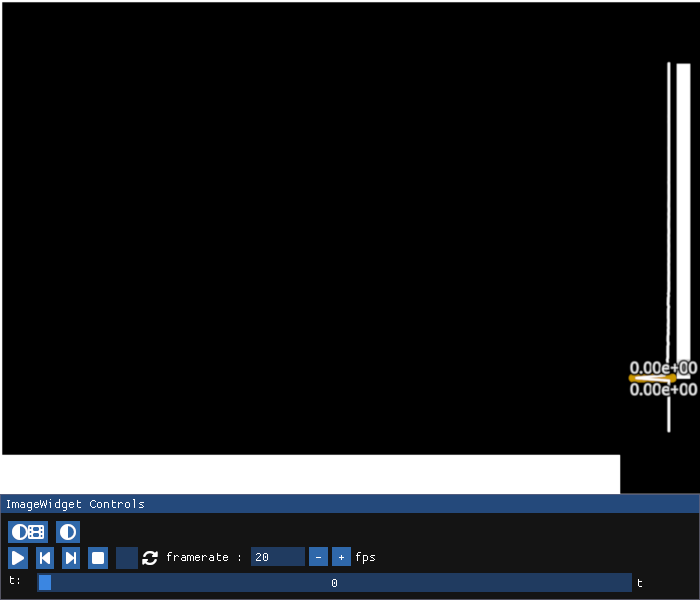

In [9]:
iw = fpl.ImageWidget(
    movie, 
    cmap="gnuplot2",
    figure_kwargs={"size": (700, 600)},
)
iw.show()

In [10]:
t, xdim, ydim = movie.shape

In [11]:
series = movie.reshape(t, xdim * ydim).T

In [12]:
series += np.vstack([np.random.normal(scale=5, size=2_000) for i in range(18)])

In [13]:
series.shape

(18, 2000)

RFBOutputContext()

JupyterWgpuCanvas(css_height='500px', css_width='700px')
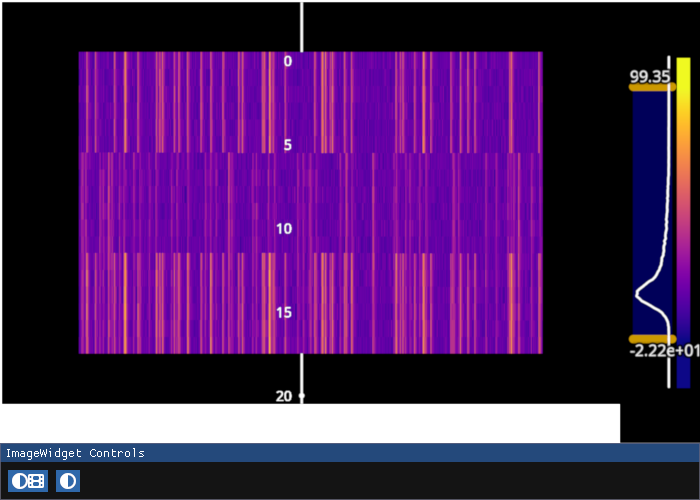

In [14]:
iw_series = fpl.ImageWidget(series, figure_kwargs={"size": (700, 500)})
iw_series.figure[0, 0].camera.maintain_aspect = False
iw_series.show()

In [15]:
st_svd = SpaceTimeSVD(series, w=16)
st_svd.compute()

Computing F, P


100%|██████████████████████████████████████████████████████████████████████| 18/18 [00:00<00:00, 22871.09it/s]


(18, 2000)
(144, 1984)


100%|██████████████████████████████████████████████████████████████████████| 18/18 [00:00<00:00, 12019.98it/s]

computing H
Computing Hp
computimng svd of Hp


RFBOutputContext()

JupyterWgpuCanvas()
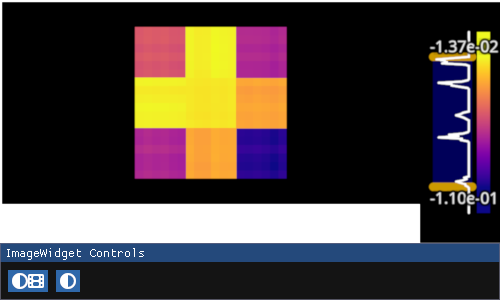

In [16]:
iw_adj = fpl.ImageWidget(st_svd.adjacency)
iw_adj.show()

best: k = n_components + 1

1) few bg pixels, real components cluster compactly, bg points are scattered
2) lots of bg pixels, bg points compact, real components less compact

In [17]:
clustering = ClusteringCPQR(st_svd.adjacency, k=2)

In [18]:
clustering.Qk.shape

(18, 2)

In [19]:
clustering.W.shape

(2, 2)

In [20]:
clustering.transformed.shape

(2, 18)

In [21]:
import pygfx
from wgpu.gui.jupyter import WgpuCanvas

canvas = WgpuCanvas()
renderer = pygfx.WgpuRenderer(target=canvas, blend_mode="weighted_plus")

fig = fpl.Figure(
    cameras="3d", 
    controller_types="orbit", 
    size=(1000, 800),
    renderer=renderer,
    canvas=canvas
)

subplot = fig[0, 0]

subplot.add_scatter(clustering.Qk, colors="r", name="vk.T", sizes=15, alpha=0.2)
subplot.add_scatter(clustering.W.T, colors="b", name="U", sizes=15, alpha=0.2)
subplot.add_scatter(clustering.transformed.T, colors="g", name="transform", sizes=15, alpha=0.2)


fig[0, 0].axes.intersection = (0, 0, 0)
fig.canvas.quality = 100
fig.show(sidecar=True)

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:264: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:276: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size


In [22]:
from fastplotlib.graphics._axes import Axes

In [23]:
if clustering.k == 2:
    basis_W = np.array([
        [*clustering.W.T[0], 0],
        [*clustering.W.T[1], 0],
        [0., 0., 1.]
    ])

elif clustering.k == 3:
    basis_W = np.array([
        clustering.W.T[0],
        clustering.W.T[1],
        clustering.W.T[2]
    ])

axes_W = Axes(fig[0, 0], intersection=(0, 0, 0), basis=basis_W)
axes_W.colors = ("b", "b", "b")

fig[0, 0].scene.add(axes_W.world_object)
fig[0, 0].add_animations(axes_W.update_using_camera)

fig[0, 0].axes.colors = ("g", "g", "g")

In [24]:
from ipywidgets import IntSlider, Button, VBox

In [25]:
clustering.transformed.argmax(axis=0)

array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0])

In [26]:
iw_movie = fpl.ImageWidget(series, figure_kwargs={"size": (1200, 600)})
iw_movie.figure.show(maintain_aspect=False)

iw = fpl.ImageWidget(
    [clustering.Qk, clustering.W, clustering.transformed.T], 
    names=["Qk", "W", "transform"], 
    figure_shape=(1, 3),
    figure_kwargs={"controller_ids": [[0, 1, 2]], "size": (1200, 350)},
)
iw.figure["transform"].set_title("W.T x Qk.T")
iw.cmap = ["bwr", "bwr", "viridis"]
iw.figure.show(maintain_aspect=False)

iw_movie.figure[0, 0].add_image(
    data=np.column_stack([clustering.transformed.argmax(axis=0)]*2),
    cmap="tab20",
    offset=(-45, 0, 0),
    name="cluster-labels"
)
iw_movie.figure[0, 0]["cluster-labels"].world_object.local.scale_x = 25

def update_movie(*args):
    movie = generate_data(
        n_timepoints=1_000, 
        n_components=slider_n_components.value,
        noise=slider_noise.value,
        n_pixels=slider_n_pixels.value,
        n_pixels_bg=slider_n_bg_pixels.value,
    )

    global st_svd
    
    st_svd = SpaceTimeSVD(movie, w=16)
    st_svd.compute()

    iw_movie.set_data(movie)
    iw_movie.figure[0, 0].auto_scale(maintain_aspect=False)

def update_clustering(*args):
    global st_svd
    
    clustering = ClusteringCPQR(st_svd.adjacency, k=slider_k.value)

    iw.set_data([clustering.Qk, clustering.W, clustering.transformed.T])
    
    for subplot in iw.figure:
        subplot.auto_scale(maintain_aspect=False)

    iw.cmap = ["bwr", "bwr", "viridis"]

    iw_movie.figure[0, 0].delete_graphic(iw_movie.figure[0, 0]["cluster-labels"])
    
    iw_movie.figure[0, 0].add_image(
        data=np.column_stack([clustering.transformed.argmax(axis=0)]*2),
        cmap="tab20",
        offset=(-45, 0, 0),
        name="cluster-labels"
    )
    iw_movie.figure[0, 0]["cluster-labels"].world_object.local.scale_x = 25

VBox([iw_movie.show(), iw.show()])

RFBOutputContext()

RFBOutputContext()

In [27]:
clustering.Qk

array([[-0.72734806, -0.68626875],
       [-0.72484791, -0.68890892],
       [-0.73732112, -0.67554243],
       [-0.72114263, -0.69278662],
       [-0.7400481 , -0.67255395],
       [-0.72155315, -0.69235905],
       [ 0.95816162, -0.28622772],
       [ 0.94950865, -0.31374085],
       [ 0.95426484, -0.29896255],
       [ 0.96342057, -0.26799403],
       [ 0.96068435, -0.27764289],
       [ 0.95558045, -0.29473039],
       [ 0.23670828, -0.97158077],
       [ 0.23872495, -0.97108723],
       [ 0.23075952, -0.97301081],
       [ 0.19162415, -0.98146838],
       [ 0.23310955, -0.97245048],
       [ 0.21521805, -0.97656602]])

In [141]:
clustering.vkT.T[:6]

clustering.vkT.T[6:12]

array([[-0.47426102, -0.4742495 , -0.46813853, -0.45795664, -0.4563111 ,
        -0.48361899],
       [-0.51522987, -0.51521865, -0.50926835, -0.4993485 , -0.49774466,
        -0.52433679],
       [-0.51436486, -0.51435364, -0.50839975, -0.49847406, -0.49686929,
        -0.52347736],
       [-0.51553265, -0.51552143, -0.50957238, -0.49965458, -0.49805107,
        -0.5246376 ],
       [-0.50764407, -0.50763279, -0.50165139, -0.49168078, -0.49006886,
        -0.51679954],
       [-0.48621284, -0.48620141, -0.48013549, -0.47002702, -0.46839316,
        -0.49550037]])

In [142]:
a = clustering.vkT.T[0]

b = clustering.vkT.T[10]

c = clustering.vkT.T[-1]

np.column_stack([a.T, b.T, c.T])

array([[-0.71454077,  0.94856566,  0.21532517],
       [-0.6995938 , -0.31658046, -0.97654241]])

In [143]:
a = np.column_stack([a.T, b.T])
np.linalg.solve(a, c)

array([0.96440466, 0.95347286])

In [145]:
import scipy

In [150]:
vk = clustering.vkT.T
idx, proj = scipy.linalg.interpolative.interp_decomp(vk.T, eps_or_k=2)

In [157]:
vk

array([[-0.71454077, -0.6995938 ],
       [-0.7467212 , -0.66513716],
       [-0.74604971, -0.66589025],
       [-0.74695616, -0.66487329],
       [-0.74082053, -0.67170302],
       [-0.72400689, -0.68979274],
       [ 0.95479022, -0.29728039],
       [ 0.95478633, -0.29729288],
       [ 0.95270369, -0.30390077],
       [ 0.94914976, -0.31482492],
       [ 0.94856566, -0.31658046],
       [ 0.95790499, -0.28708541],
       [ 0.20138736, -0.97951168],
       [ 0.23025218, -0.97313099],
       [ 0.20750693, -0.97823355],
       [ 0.16111076, -0.98693633],
       [ 0.2192706 , -0.97566408],
       [ 0.21532517, -0.97654241]])

In [156]:
idx

array([ 4, 13,  2,  3,  0,  5,  6,  7,  8,  9, 10, 11, 12,  1, 14, 15, 16,
       17], dtype=int32)

In [166]:
proj.shape

(2, 16)

In [168]:
np.round(proj)

array([[ 1.,  1.,  1.,  1., -1., -1., -1., -1., -1., -1.,  0.,  1.,  0.,
         0.,  0.,  0.],
       [-0., -0.,  0.,  0.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -0.,  1.,
         1.,  1.,  1.]])

In [172]:
proj

array([[ 1.00428321,  1.00502322,  0.97812671,  0.98607012, -0.98299406,
        -0.98298645, -0.97893407, -0.97211143, -0.97100059, -0.98913686,
         0.0337588 ,  1.00483147,  0.0266213 ,  0.0804754 ,  0.01287126,
         0.01748725],
       [-0.00892974, -0.01048557,  0.0437589 ,  0.02820429,  0.98399955,
         0.98400714,  0.98800033,  0.99451677,  0.99555403,  0.97776315,
         0.98325487, -0.01008206,  0.9868681 ,  0.95863842,  0.99371865,
         0.99143504]])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
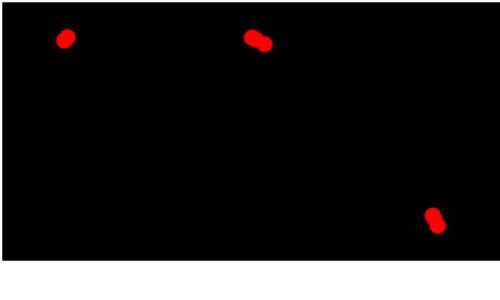

In [174]:
fig_proj = fpl.Figure()
fig_proj[0, 0].add_scatter(proj.T, sizes=15, colors="r")
fig_proj.show()

In [177]:
rounded_proj = np.round(proj)
rounded_proj.T

array([[ 1., -0.],
       [ 1., -0.],
       [ 1.,  0.],
       [ 1.,  0.],
       [-1.,  1.],
       [-1.,  1.],
       [-1.,  1.],
       [-1.,  1.],
       [-1.,  1.],
       [-1.,  1.],
       [ 0.,  1.],
       [ 1., -0.],
       [ 0.,  1.],
       [ 0.,  1.],
       [ 0.,  1.],
       [ 0.,  1.]])

In [193]:
basis = np.unique(rounded_proj.T, axis=0)

In [194]:
basis

array([[-1.,  1.],
       [ 0.,  1.],
       [ 1., -0.]])

In [195]:
basis[0] = basis[0] + basis[-1]
basis

array([[ 0.,  1.],
       [ 0.,  1.],
       [ 1., -0.]])

In [196]:
basis[1] = basis[1] + basis[-1]

In [197]:
basis

array([[ 0.,  1.],
       [ 1.,  1.],
       [ 1., -0.]])

In [175]:
fig_proj[0, 0].axes.intersection = (0, 0, 0)

In [126]:
clustering.pivots

array([ 2, 13,  0,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12,  1, 14, 15, 16,
       17], dtype=int32)

In [127]:
clustering.U

array([[-0.88675854,  0.46223294],
       [-0.46223294, -0.88675854]])

In [128]:
clustering.transformed.T

array([[ 0.95700043,  0.2900865 ],
       [ 0.96960971,  0.24465692],
       [ 0.96936236,  0.24563511],
       [ 0.96969609,  0.24431433],
       [ 0.96741219,  0.25320673],
       [ 0.96086422,  0.27701977],
       [-0.7092556 ,  0.70495142],
       [-0.70924637,  0.7049607 ],
       [-0.70434518,  0.70985763],
       [-0.69614421,  0.71790197],
       [-0.69481478,  0.71918872],
       [-0.71673009,  0.69735068],
       [ 0.2741806 ,  0.96167822],
       [ 0.24563511,  0.96936236],
       [ 0.26816323,  0.96337349],
       [ 0.31332814,  0.94964492],
       [ 0.25654401,  0.96653255],
       [ 0.26044864,  0.9654877 ]])

In [129]:
thres_labels

array([[1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1]])

In [130]:
clustering.U

array([[-0.88675854,  0.46223294],
       [-0.46223294, -0.88675854]])

In [131]:
clustering.transformed

array([[ 0.95700043,  0.96960971,  0.96936236,  0.96969609,  0.96741219,
         0.96086422, -0.7092556 , -0.70924637, -0.70434518, -0.69614421,
        -0.69481478, -0.71673009,  0.2741806 ,  0.24563511,  0.26816323,
         0.31332814,  0.25654401,  0.26044864],
       [ 0.2900865 ,  0.24465692,  0.24563511,  0.24431433,  0.25320673,
         0.27701977,  0.70495142,  0.7049607 ,  0.70985763,  0.71790197,
         0.71918872,  0.69735068,  0.96167822,  0.96936236,  0.96337349,
         0.94964492,  0.96653255,  0.9654877 ]])

In [132]:
thres_labels = (clustering.transformed.T > 0.2).astype(int)
thres_labels

array([[1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 1]])

In [133]:
cluster_labels.cmap = "tab10"

In [134]:
selector_movie = iw_movie.managed_graphics[0].add_linear_selector(axis="y")
selector_vkT = iw.figure["vk.T"]["image_widget_managed"].add_linear_selector(axis="y")
selector_transform = iw.figure["transform"]["image_widget_managed"].add_linear_selector(axis="y")
selectors = [selector_movie, selector_vkT, selector_transform]

In [135]:
class IndexStore:
    def __init__(self):
        self.index: int = None

    def set_index(self, new_index: int, source_graphic: fpl.LinearSelector | fpl.ScatterGraphic):
        self._set_points(new_index)
        self._set_linear_selectors(new_index, source_graphic)

    def _set_points(self, index: int):
        # reset colors
        subplot["vk.T"].colors = (1, 0, 0, 0.2)
        subplot["vk.T"].sizes = 15
        
        subplot["transform"].colors = (0, 1, 0, 0.2)
        subplot["transform"].sizes = 15
        
        # set colors and size
        subplot["vk.T"].colors[index] = "yellow"
        subplot["vk.T"].sizes[index] = 25
        
        subplot["transform"].colors[index] = "cyan"
        subplot["transform"].sizes[index] = 25

    def _set_linear_selectors(self, index: int, source_graphic):
        with fpl.pause_events(*selectors):
            for selector in selectors:
                if source_graphic is selector:
                    continue
                selector.selection = index

    def _scatter_callback(self, ev):
        index = ev.pick_info["vertex_index"]
        self.set_index(index, ev.graphic)
    
    def register_scatter(self, graphic: fpl.ScatterGraphic):
        graphic.add_event_handler(self._scatter_callback, "click")

    def _linear_selector_callback(self, ev):
        index = ev.get_selected_index()
        self.set_index(index, ev.graphic)
    
    def register_linear_selector(self, selector: fpl.LinearSelector):
        selector.add_event_handler(self._linear_selector_callback, "selection")

In [136]:
index_store = IndexStore()

index_store.register_scatter(subplot["vk.T"])
index_store.register_scatter(subplot["transform"])

index_store.register_linear_selector(selector_movie)
index_store.register_linear_selector(selector_vkT)
index_store.register_linear_selector(selector_transform)